# 07. Comparacion de modelos

Este cuaderno compara todos los modelos registrados que tienen resultados de prueba. Lee los
resultados con `cargar_resultados`, de modo que puede ejecutarse en cualquier momento: los modelos que
aun no se han entrenado se omiten y aparecen al volver a ejecutarlo.

Se reportan dos alcances. El alcance DR mide la severidad solo sobre las fotografias diagnosticadas
con sequia, que es la tarea que aprenden los modelos. El alcance global incluye los demas
diagnosticos, a los que la regla de `completar_con_regla` asigna magnitud 0.

## Entorno

In [1]:
import sys
from pathlib import Path


def raiz_proyecto():
    for candidato in [Path.cwd(), *Path.cwd().parents]:
        if (candidato / "src").is_dir():
            return candidato
    raise RuntimeError("No se encontro la raiz del proyecto")


RAIZ = raiz_proyecto()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

from src.config import DANO_SEQUIA, PALETA, SECUENCIA_COLORES, TEMPORADAS
from src.evaluacion import cargar_resultados, metricas, metricas_por_grupo, tabla_predicciones
from src.graficos import aplicar_estilo, barras_comparativas, guardar_figura
from src.registro_modelos import crear_registro

aplicar_estilo()

## Modelos con resultados

In [2]:
registro = crear_registro()
resultados = {mid: r for mid in registro if (r := cargar_resultados(mid)) is not None}
tablas = {mid: tabla_predicciones(r) for mid, r in resultados.items()}
nombres = {mid: registro[mid].nombre for mid in resultados}
colores = {mid: SECUENCIA_COLORES[i % len(SECUENCIA_COLORES)] for i, mid in enumerate(resultados)}
sin_resultados = [mid for mid in registro if mid not in resultados]
print(f"con resultados: {list(resultados)}")
print(f"sin resultados: {sin_resultados}")

con resultados: ['constante', 'resnet50']
sin resultados: []


## Metricas por modelo

In [3]:
filas = []
for mid, tabla in tablas.items():
    sequia = tabla[tabla["dano"] == DANO_SEQUIA]
    for alcance, datos in (("DR", sequia), ("global", tabla)):
        valores = metricas(datos["real"], datos["predicho"])
        filas.append({"modelo": nombres[mid], "alcance": alcance, **valores})
errores = pd.DataFrame(filas)
errores.round(3)

,modelo,alcance,n,mae,rmse,r2
0,Predictor constante,DR,834,19.783,24.085,-0.001
1,Predictor constante,global,4628,3.565,10.224,0.699
2,ResNet50,DR,834,15.028,18.806,0.390
3,ResNet50,global,4628,2.708,7.983,0.816


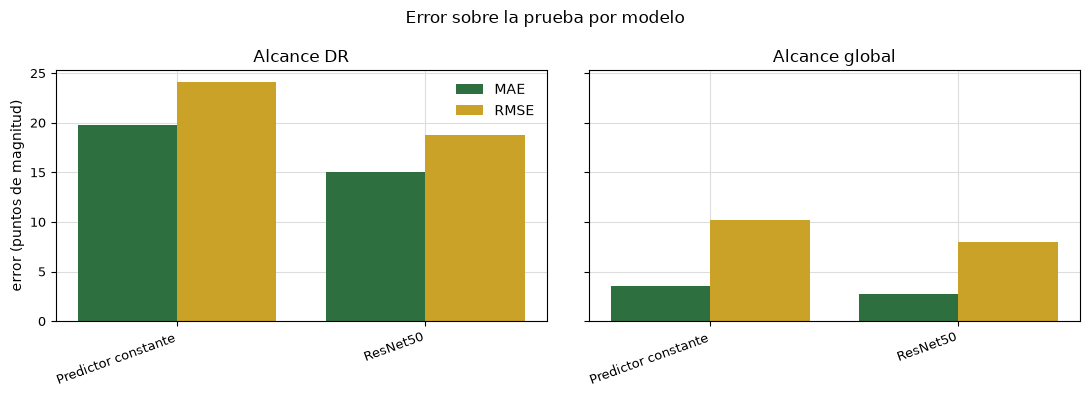

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
posiciones = np.arange(len(tablas))
for ax, alcance in zip(ejes, ("DR", "global")):
    datos = errores[errores["alcance"] == alcance].set_index("modelo").loc[list(nombres.values())]
    ax.bar(posiciones - 0.2, datos["mae"], width=0.4, label="MAE", color=PALETA["principal"])
    ax.bar(posiciones + 0.2, datos["rmse"], width=0.4, label="RMSE", color=PALETA["secundario"])
    ax.set_xticks(posiciones)
    ax.set_xticklabels(datos.index, rotation=20, ha="right")
    ax.set_title(f"Alcance {alcance}")
ejes[0].set_ylabel("error (puntos de magnitud)")
ejes[0].legend()
fig.suptitle("Error sobre la prueba por modelo")
fig.tight_layout()
guardar_figura(fig, "07_comparacion_errores");

## Magnitud real contra predicha

Cada panel muestra los registros DR de prueba. La magnitud real toma valores de 10 en 10, por lo que
se agrega un desplazamiento horizontal pequeno para ver la densidad de puntos. La linea discontinua
es la prediccion perfecta y los rombos marcan la prediccion media para cada nivel real.

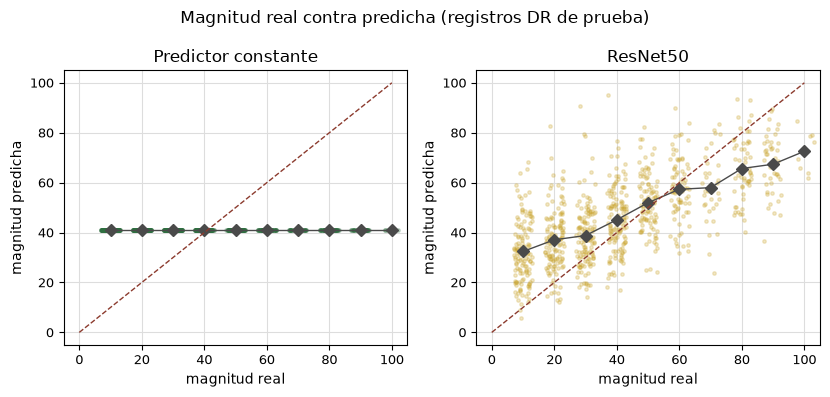

In [5]:
rng = np.random.default_rng(42)
columnas = min(3, len(tablas))
filas_paneles = -(-len(tablas) // columnas)
fig, ejes = plt.subplots(filas_paneles, columnas, figsize=(4.2 * columnas, 4 * filas_paneles), squeeze=False)
for ax, (mid, tabla) in zip(ejes.flat, tablas.items()):
    sequia = tabla[tabla["dano"] == DANO_SEQUIA]
    ax.scatter(sequia["real"] + rng.uniform(-3, 3, len(sequia)), sequia["predicho"], s=6, alpha=0.25, color=colores[mid])
    medias = sequia.groupby("real")["predicho"].mean()
    ax.plot(medias.index, medias.values, marker="D", color=PALETA["neutro"], linewidth=1)
    ax.plot([0, 100], [0, 100], linestyle="--", color=PALETA["terciario"], linewidth=1)
    ax.set_xlim(-5, 105)
    ax.set_ylim(-5, 105)
    ax.set_title(nombres[mid])
    ax.set_xlabel("magnitud real")
    ax.set_ylabel("magnitud predicha")
for ax in list(ejes.flat)[len(tablas):]:
    ax.set_visible(False)
fig.suptitle("Magnitud real contra predicha (registros DR de prueba)")
fig.tight_layout()
guardar_figura(fig, "07_real_vs_predicho");

## Error por temporada

Se calcula el RMSE de los registros DR de prueba por temporada. Una diferencia grande entre
temporadas indica que el modelo depende de condiciones de captura propias de cada temporada.

,Predictor constante,ResNet50
temporada,,
LR2020,22.99,17.20
SR2020,30.04,20.70
LR2021,20.15,17.93
SR2021,22.51,18.41


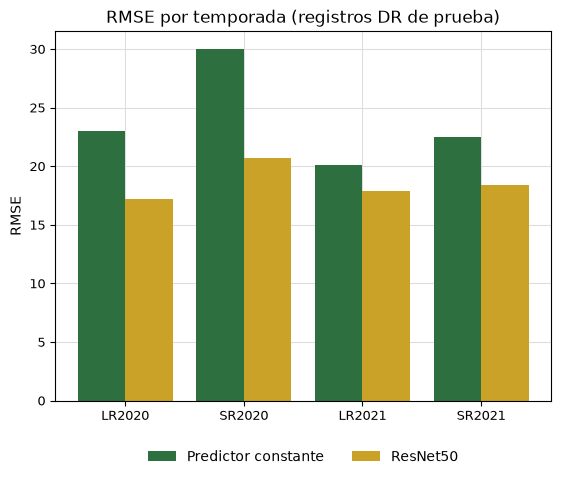

In [6]:
por_temporada = pd.concat(
    {nombres[mid]: metricas_por_grupo(tabla[tabla["dano"] == DANO_SEQUIA], "temporada").set_index("grupo")["rmse"]
     for mid, tabla in tablas.items()},
    axis=1,
)
por_temporada = por_temporada.reindex([t for t in TEMPORADAS if t in por_temporada.index])
por_temporada.index.name = "temporada"
fig = barras_comparativas(por_temporada, list(por_temporada.columns), "RMSE por temporada (registros DR de prueba)", "RMSE")
fig.axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=min(4, len(por_temporada.columns)))
guardar_figura(fig, "07_error_por_temporada")
por_temporada.round(2)

## Tiempos

El tiempo de entrenamiento incluye la busqueda de hiperparametros y el reentrenamiento final. El
tiempo de inferencia es la media por imagen DR de prueba. Los modelos se entrenaron en equipos
distintos, por lo que los tiempos solo son comparables en orden de magnitud. Ambos ejes usan escala
logaritmica; los valores menores que 0.0001 se dibujan en ese minimo y su etiqueta indica el valor real.

,entrenamiento_s,inferencia_ms,dispositivo
Predictor constante,0.000056,0.000008,cpu
ResNet50,683.227935,12.993011,mps


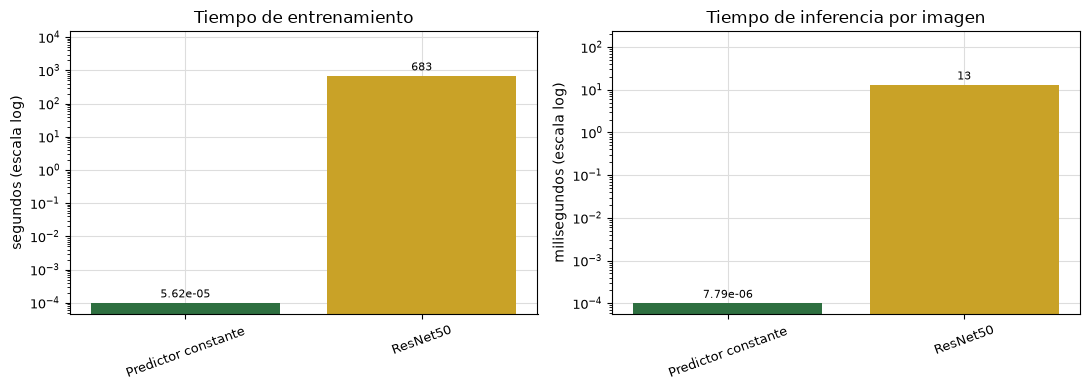

In [7]:
tiempos = pd.DataFrame(
    {"entrenamiento_s": {nombres[m]: r.tiempo_entrenamiento_s for m, r in resultados.items()},
     "inferencia_ms": {nombres[m]: r.tiempo_inferencia_ms for m, r in resultados.items()},
     "dispositivo": {nombres[m]: r.hiperparametros.get("dispositivo", "cpu") for m, r in resultados.items()}}
)
fig, (ax_entrenamiento, ax_inferencia) = plt.subplots(1, 2, figsize=(11, 4))
lista_colores = [colores[m] for m in resultados]
for ax, columna, titulo, unidad in (
    (ax_entrenamiento, "entrenamiento_s", "Tiempo de entrenamiento", "segundos"),
    (ax_inferencia, "inferencia_ms", "Tiempo de inferencia por imagen", "milisegundos"),
):
    barras = ax.bar(tiempos.index, tiempos[columna].clip(lower=1e-4), color=lista_colores)
    ax.bar_label(barras, labels=[f"{v:.3g}" for v in tiempos[columna]], padding=2, fontsize=8)
    ax.set_yscale("log")
    ax.set_ylim(top=ax.get_ylim()[1] * 10)
    ax.set_title(titulo)
    ax.set_ylabel(f"{unidad} (escala log)")
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
guardar_figura(fig, "07_tiempos")
tiempos

## Tabla final

In [8]:
final = (
    errores.pivot(index="modelo", columns="alcance", values=["mae", "rmse", "r2"])
    .pipe(lambda t: t.set_axis([f"{metrica}_{alcance}" for metrica, alcance in t.columns], axis=1))
    .join(tiempos[["entrenamiento_s", "inferencia_ms"]])
    .sort_values("rmse_DR")
)
final.round(3)

,mae_DR,mae_global,rmse_DR,rmse_global,r2_DR,r2_global,entrenamiento_s,inferencia_ms
modelo,,,,,,,,
ResNet50,15.028,2.708,18.806,7.983,0.390,0.816,683.228,12.993
Predictor constante,19.783,3.565,24.085,10.224,-0.001,0.699,0.000,0.000


## Recomendacion

El criterio principal es el RMSE sobre los registros DR de prueba, porque la tarea de los modelos es
estimar la severidad de la sequia y el RMSE penaliza mas los errores grandes, que son los que mas
afectan el monto de una indemnizacion. Un modelo solo se recomienda si mejora al predictor constante.
Si dos modelos quedan a menos de un punto de RMSE, se prefiere el de menor tiempo de inferencia,
porque la aplicacion responde a cada fotografia en linea. La celda siguiente aplica el criterio a los
modelos disponibles al momento de ejecutar el cuaderno.

In [9]:
referencia = final.loc[nombres["constante"]] if "constante" in nombres else None
candidatos = final.drop(index=nombres.get("constante"), errors="ignore")
if referencia is not None:
    candidatos = candidatos[candidatos["rmse_DR"] < referencia["rmse_DR"]]
if candidatos.empty:
    print("Ningun modelo mejora al predictor constante.")
else:
    cercanos = candidatos[candidatos["rmse_DR"] <= candidatos["rmse_DR"].min() + 1]
    elegido = cercanos["inferencia_ms"].idxmin()
    fila = final.loc[elegido]
    print(f"Modelo recomendado: {elegido}")
    print(f"  RMSE DR {fila['rmse_DR']:.2f}, MAE DR {fila['mae_DR']:.2f}, R2 DR {fila['r2_DR']:.3f}")
    if referencia is not None:
        mejora = 1 - fila["rmse_DR"] / referencia["rmse_DR"]
        print(f"  Reduce el RMSE DR del predictor constante en {100 * mejora:.1f} %")
    print(f"  Inferencia: {fila['inferencia_ms']:.2f} ms por imagen")

Modelo recomendado: ResNet50
  RMSE DR 18.81, MAE DR 15.03, R2 DR 0.390
  Reduce el RMSE DR del predictor constante en 21.9 %
  Inferencia: 12.99 ms por imagen


Con los resultados disponibles en esta ejecucion, la ResNet50 es el unico modelo que aprende de
la imagen y reduce el RMSE DR del predictor constante de 24.1 a 18.8 puntos, con R² de 0.39. La
grafica de real contra predicho muestra su limitacion principal: comprime las predicciones hacia el
centro, sobrestima los danos leves y subestima los severos. Su costo de inferencia, unos 13 ms por
imagen en la GPU de una Mac, es compatible con el uso en linea de la aplicacion. La recomendacion debe
revisarse al volver a ejecutar el cuaderno con Random Forest y DenseNet121.